Part a

C:\Users\TamirLand\AppData\Local\Temp\ipykernel_5028\504442086.py:17: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  samples1 = np.random.multivariate_normal(mu1, Sigma1, num_samples)
C:\Users\TamirLand\AppData\Local\Temp\ipykernel_5028\504442086.py:18: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  samples2 = np.random.multivariate_normal(mu2, Sigma2, num_samples)
C:\Users\TamirLand\AppData\Local\Temp\ipykernel_5028\504442086.py:19: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  samples3 = np.random.multivariate_normal(mu3, Sigma3, num_samples)


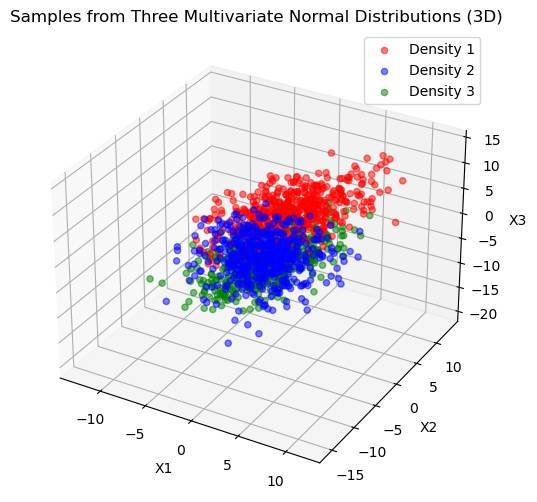

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Defining the mean vectors and covariance matrices from the probelm 
mu1 = np.array([1, 2, 4])
mu2 = np.array([2, -6, 2])
mu3 = np.array([-3, 5, -10])

Sigma1 = np.array([[9, 4, 10], [4, 9, 6], [10, 6, 4]])
Sigma2 = np.array([[8, 1, 0], [1, 6, 6], [0, 6, 3]])
Sigma3 = np.array([[2, 6, 8], [6, 3, 9], [8, 9, 5]])

num_samples = 500

# Generating samples from each distribution
samples1 = np.random.multivariate_normal(mu1, Sigma1, num_samples)
samples2 = np.random.multivariate_normal(mu2, Sigma2, num_samples)
samples3 = np.random.multivariate_normal(mu3, Sigma3, num_samples)

# 3D ploting for the original samples
fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(samples1[:, 0], samples1[:, 1], samples1[:, 2], color='red', label='Density 1', alpha=0.5)
ax.scatter(samples2[:, 0], samples2[:, 1], samples2[:, 2], color='blue', label='Density 2', alpha=0.5)
ax.scatter(samples3[:, 0], samples3[:, 1], samples3[:, 2], color='green', label='Density 3', alpha=0.5)
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
ax.set_title('Samples from Three Multivariate Normal Distributions (3D)')
ax.legend()
plt.show()

Part b

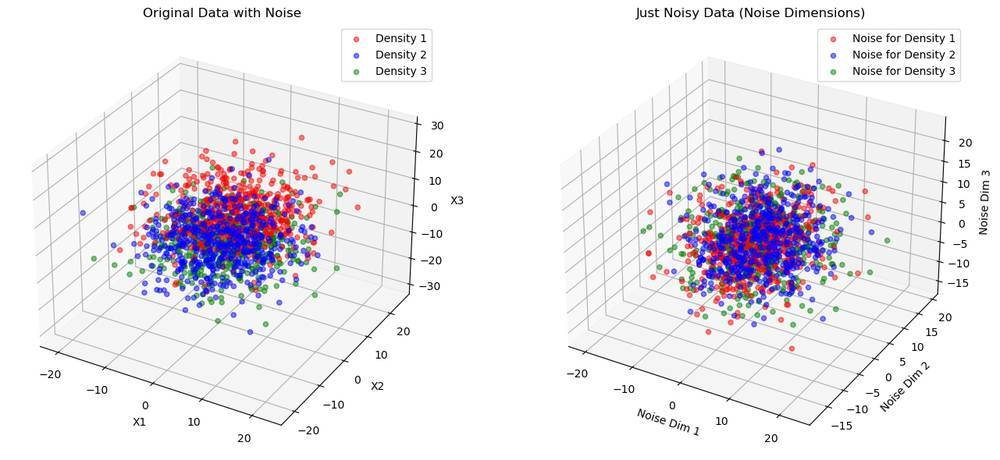

In [2]:
# Defining the mean and standard deviation for the noise distribution from the probelm 
mu_noise = 1
sigma_noise = 6
num_noise_dimensions = 50

# Generating random noise dimensions for each sample from N(1, 6)
noise1 = np.random.normal(mu_noise, sigma_noise, (num_samples, num_noise_dimensions))
noise2 = np.random.normal(mu_noise, sigma_noise, (num_samples, num_noise_dimensions))
noise3 = np.random.normal(mu_noise, sigma_noise, (num_samples, num_noise_dimensions))

# Adding noise to the original 3 dimensions of the data (element-wise)
noisy_samples1 = samples1 + np.random.normal(mu_noise, sigma_noise, samples1.shape)
noisy_samples2 = samples2 + np.random.normal(mu_noise, sigma_noise, samples2.shape)
noisy_samples3 = samples3 + np.random.normal(mu_noise, sigma_noise, samples3.shape)

fig = plt.figure(figsize=(14, 6))

# 3D plot for the noisy data (original data + noise)
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(noisy_samples1[:, 0], noisy_samples1[:, 1], noisy_samples1[:, 2], color='red', label='Density 1', alpha=0.5)
ax1.scatter(noisy_samples2[:, 0], noisy_samples2[:, 1], noisy_samples2[:, 2], color='blue', label='Density 2', alpha=0.5)
ax1.scatter(noisy_samples3[:, 0], noisy_samples3[:, 1], noisy_samples3[:, 2], color='green', label='Density 3', alpha=0.5)
ax1.set_xlabel('X1')
ax1.set_ylabel('X2')
ax1.set_zlabel('X3')
ax1.set_title('Original Data with Noise')
ax1.legend()

# Ploting the just noisy data
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(noise1[:, 0], noise1[:, 1], noise1[:, 2], color='red', label='Noise for Density 1', alpha=0.5)
ax2.scatter(noise2[:, 0], noise2[:, 1], noise2[:, 2], color='blue', label='Noise for Density 2', alpha=0.5)
ax2.scatter(noise3[:, 0], noise3[:, 1], noise3[:, 2], color='green', label='Noise for Density 3', alpha=0.5)
ax2.set_xlabel('Noise Dim 1')
ax2.set_ylabel('Noise Dim 2')
ax2.set_zlabel('Noise Dim 3')
ax2.set_title('Just Noisy Data (Noise Dimensions)')
ax2.legend()
plt.tight_layout()
plt.show()


Part c

In [3]:
augmented_samples1 = np.hstack([samples1, noise1])
augmented_samples2 = np.hstack([samples2, noise2])
augmented_samples3 = np.hstack([samples3, noise3])

# Concatenating all augmented datasets to form a combined dataset
combined_data = np.vstack([augmented_samples1, augmented_samples2, augmented_samples3])

# Computing the covariance matrix of the combined dataset
cov_matrix = np.cov(combined_data, rowvar=False)

print("Covariance Matrix Shape:", cov_matrix.shape)

Covariance Matrix Shape: (53, 53)


Part d

In [8]:
# Standardize the data (mean = 0, std = 1)
mean = np.mean(combined_data, axis=0)
std = np.std(combined_data, axis=0)
standardized_data = (combined_data - mean) / std

# Computing the covariance matrix
cov_matrix = np.cov(standardized_data, rowvar=False)
# Computing eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
# Sorting the eigenvalues and eigenvectors in descending order
sorted_indices = np.argsort(eigenvalues)[::-1] 
sorted_eigenvalues = eigenvalues[sorted_indices]
sorted_eigenvectors = eigenvectors[:, sorted_indices]

# Getting the top 10 eigenvalues and eigenvectors (that are sorted in above)
top_10_eigenvalues = sorted_eigenvalues[:10]
top_10_eigenvectors = sorted_eigenvectors[:, :10]

print("Top 10 Eigenvalues:")
print(top_10_eigenvalues)
print("\nTop 10 Eigenvectors:")
for i, eigenvector in enumerate(top_10_eigenvectors.T):
    print(f"Eigenvector {i + 1}: {eigenvector}")

Top 10 Eigenvalues:
[1.879511   1.3882962  1.34642543 1.32972083 1.28921511 1.27537088
 1.24504523 1.23232997 1.2216475  1.20137921]

Top 10 Eigenvectors:
Eigenvector 1: [ 0.59964963 -0.41708043  0.6329127  -0.00986385  0.01817222  0.00591572
  0.01228164 -0.05723841  0.05816448  0.03957013 -0.00346978 -0.01720771
  0.02201125  0.0093815  -0.00335549 -0.03462899 -0.04590934 -0.01568414
 -0.0676962  -0.01943146  0.09071855 -0.04560627 -0.04692932 -0.04067401
  0.02215293 -0.00804906  0.02082015 -0.03584241  0.06763844 -0.01192195
  0.00864262  0.01379979  0.01610347 -0.01963549 -0.0172589  -0.0349944
 -0.09905871 -0.01306951  0.02562383 -0.00352187 -0.04456218 -0.03462181
 -0.02060256 -0.00475739  0.06829824 -0.03760327 -0.01038087 -0.04120644
 -0.03338612 -0.02190035  0.011261   -0.00180146  0.01263635]
Eigenvector 2: [-0.03204192 -0.16552539  0.01625401  0.11627353  0.21279805 -0.12526414
 -0.02920793  0.12600801 -0.19092424 -0.1082161  -0.12232109  0.19606311
 -0.06479412 -0.27882893

Part e

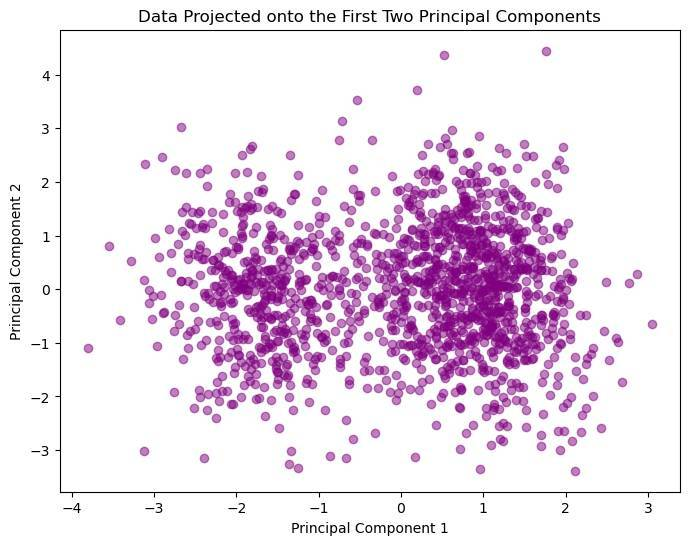

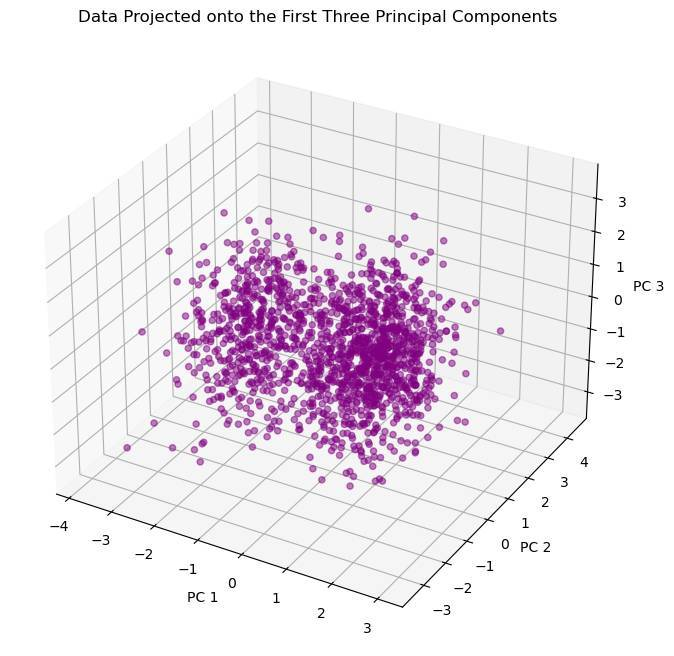

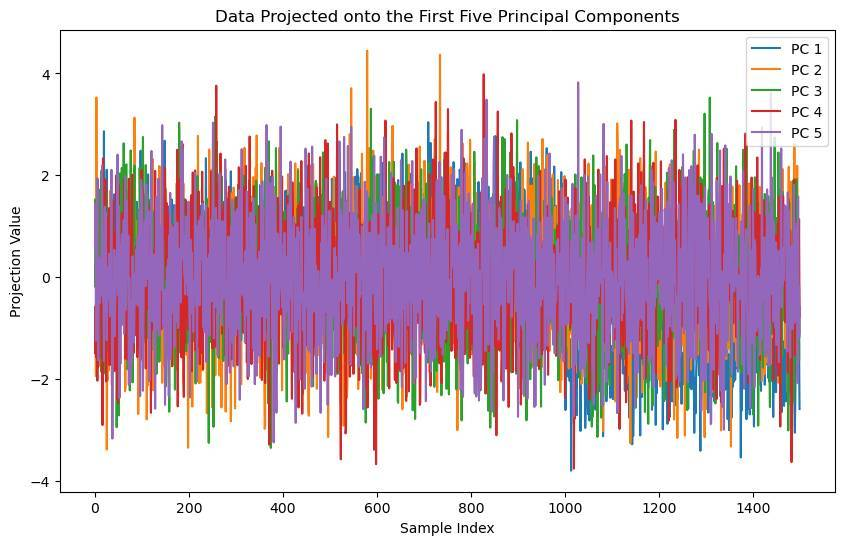

In [10]:
# Standardizing & Computing the covariance matrix & eigenvalues and eigenvectors with sorting
mean = np.mean(augmented_data, axis=0)
std = np.std(augmented_data, axis=0)
standardized_data = (augmented_data - mean) / std
cov_matrix = np.cov(standardized_data, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
sorted_indices = np.argsort(eigenvalues)[::-1]
sorted_eigenvalues = eigenvalues[sorted_indices]
sorted_eigenvectors = eigenvectors[:, sorted_indices]

# Projecting the data onto the top 2 principal components
projected_2d = standardized_data.dot(sorted_eigenvectors[:, :2])
# Plotting the data projected onto the first two principal components
plt.figure(figsize=(8, 6))
plt.scatter(projected_2d[:, 0], projected_2d[:, 1], alpha=0.5, color='purple')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Data Projected onto the First Two Principal Components')
plt.show()

# Projecting the data onto the top 3 principal components (3D scatter plot)
projected_3d = standardized_data.dot(sorted_eigenvectors[:, :3])
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projected_3d[:, 0], projected_3d[:, 1], projected_3d[:, 2], alpha=0.5, color='purple')
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
ax.set_zlabel('PC 3')
ax.set_title('Data Projected onto the First Three Principal Components')
plt.show()

# Projecting the data onto the top 5 principal components (plotting 5 components)
projected_5d = standardized_data.dot(sorted_eigenvectors[:, :5])
plt.figure(figsize=(10, 6))
for i in range(5):
    plt.plot(projected_5d[:, i], label=f'PC {i+1}')
plt.xlabel('Sample Index')
plt.ylabel('Projection Value')
plt.title('Data Projected onto the First Five Principal Components')
plt.legend()
plt.show()

Part f

C:\Program Files\Anaconda\lib\site-packages\matplotlib\collections.py:196: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


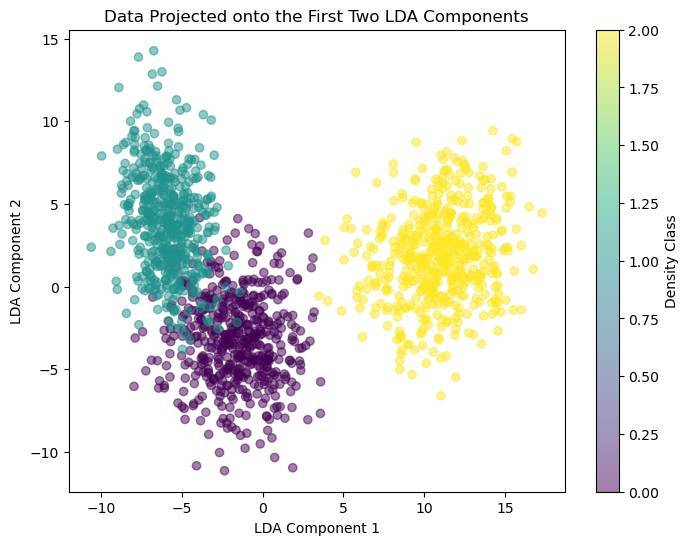

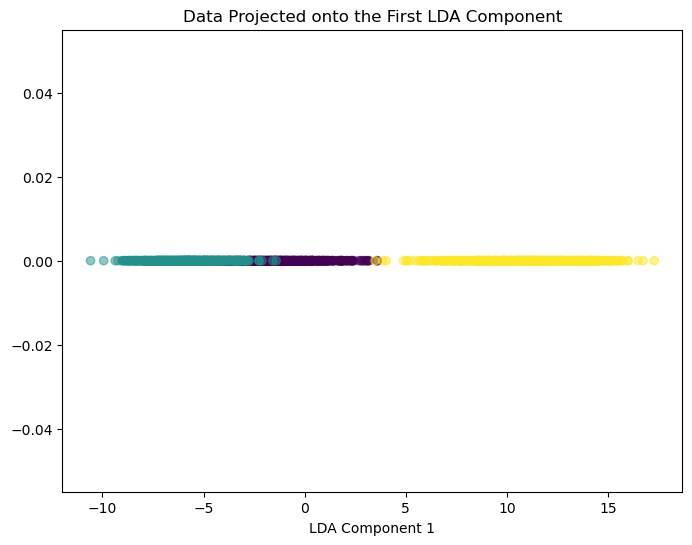

C:\Program Files\Anaconda\lib\site-packages\matplotlib\cbook\__init__.py:1298: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


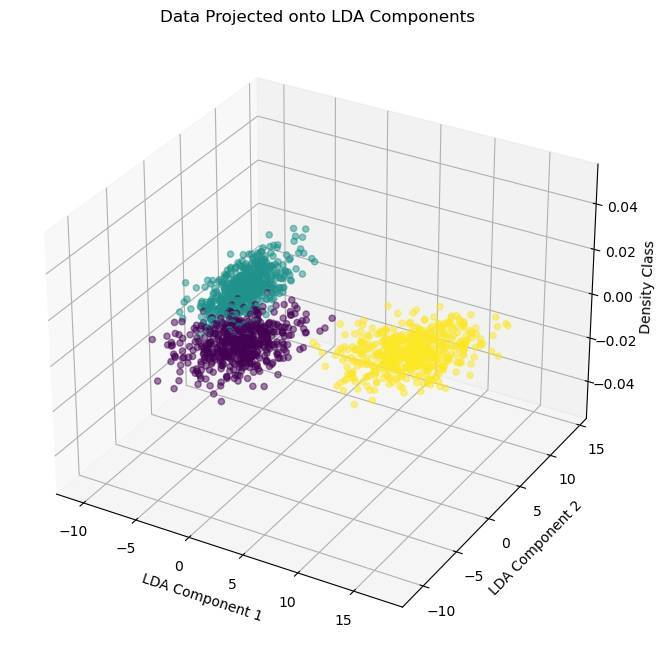

In [11]:
# Define the labels and data
labels = np.array([0] * num_samples + [1] * num_samples + [2] * num_samples)
# Concatenating the augmented data from each class
data = np.vstack([augmented_samples1, augmented_samples2, augmented_samples3])
# Computing the mean vectors for each class
mean_vectors = []
for c in range(3):  # 3 classes (0, 1, 2)
    class_data = data[labels == c]
    mean_vectors.append(np.mean(class_data, axis=0))
mean_vectors = np.array(mean_vectors)

# Computing the scatter matrices between-class scatter matrix (to reach SB)
overall_mean = np.mean(data, axis=0)
SB = np.zeros((data.shape[1], data.shape[1]))
for c, mean_vec in enumerate(mean_vectors):
    n_c = data[labels == c].shape[0]  # Number of samples in class c
    mean_vec = mean_vec.reshape(-1, 1)
    overall_mean = overall_mean.reshape(-1, 1)
    SB += n_c * (mean_vec - overall_mean).dot((mean_vec - overall_mean).T)

# Then, we need within-class scatter matrix (to reach SW)
SW = np.zeros((data.shape[1], data.shape[1]))
for c, mean_vec in enumerate(mean_vectors):
    class_scatter = np.zeros((data.shape[1], data.shape[1]))
    class_data = data[labels == c]
    for row in class_data:
        row = row.reshape(-1, 1)
        mean_vec = mean_vec.reshape(-1, 1)
        class_scatter += (row - mean_vec).dot((row - mean_vec).T)
    SW += class_scatter

# Computing the eigenvalues and eigenvectors of SW^(-1) * SB
SW_inv = np.linalg.inv(SW)
eigenvalues, eigenvectors = np.linalg.eig(SW_inv.dot(SB))
# Sortting
sorted_indices = np.argsort(eigenvalues)[::-1]
sorted_eigenvalues = eigenvalues[sorted_indices]
sorted_eigenvectors = eigenvectors[:, sorted_indices]
# Projecting the data onto the first 2 LDA components
lda_2d = data.dot(sorted_eigenvectors[:, :2])
# Plotting the data projected onto the first two LDA components
plt.figure(figsize=(8, 6))
plt.scatter(lda_2d[:, 0], lda_2d[:, 1], c=labels, cmap='viridis', alpha=0.5)
plt.xlabel('LDA Component 1')
plt.ylabel('LDA Component 2')
plt.title('Data Projected onto the First Two LDA Components')
plt.colorbar(label='Density Class')
plt.show()
# 1 LDA component (1D plot)
lda_1d = data.dot(sorted_eigenvectors[:, :1])
plt.figure(figsize=(8, 6))
plt.scatter(lda_1d[:, 0], np.zeros_like(lda_1d[:, 0]), c=labels, cmap='viridis', alpha=0.5)
plt.xlabel('LDA Component 1')
plt.title('Data Projected onto the First LDA Component')
plt.show()
# 3 components (but max 2 components for 3 classes)
lda_3d = data.dot(sorted_eigenvectors[:, :2])
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(lda_3d[:, 0], lda_3d[:, 1], c=labels, cmap='viridis', alpha=0.5)
ax.set_xlabel('LDA Component 1')
ax.set_ylabel('LDA Component 2')
ax.set_zlabel('Density Class')
ax.set_title('Data Projected onto LDA Components')
plt.show()

Part h

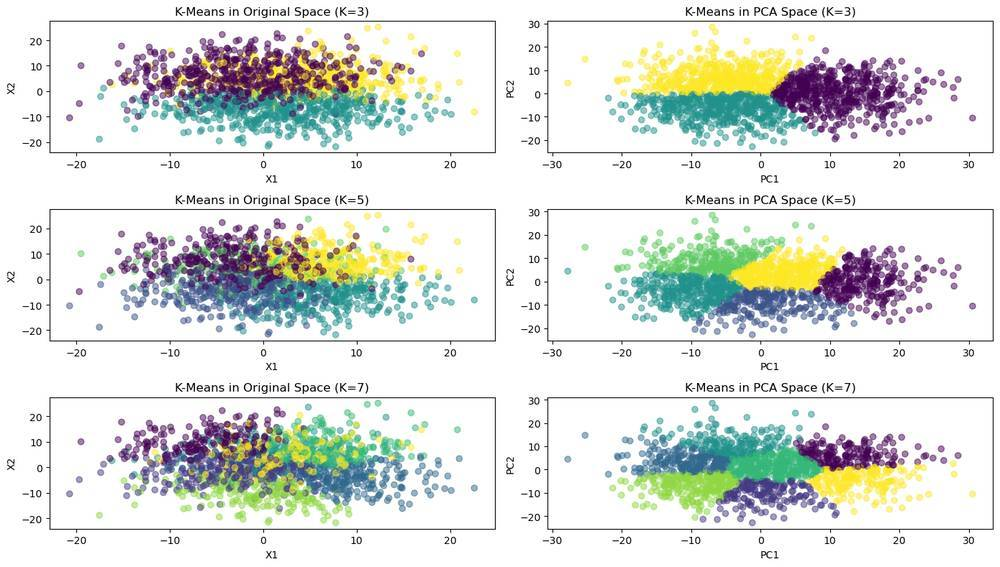

In [12]:
def kmeans_manual(X, K, max_iters=100, tol=1e-4):
    np.random.seed(69)
    initial_centroids = X[np.random.choice(X.shape[0], K, replace=False)]
    centroids = initial_centroids
    prev_centroids = centroids.copy()
    labels = np.zeros(X.shape[0])
    for _ in range(max_iters):
        # Assigning each point to the nearest centroid
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)
        # Recomputing centroids as the mean of the points assigned to each centroid
        new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(K)])
        # Checking for convergence (if the centroids don't change)
        if np.all(np.abs(new_centroids - prev_centroids) < tol):
            break
        prev_centroids = new_centroids.copy()
        centroids = new_centroids
    return centroids, labels

K_values = [3, 5, 7]
fig, axes = plt.subplots(len(K_values), 2, figsize=(14, 8))
for i, K in enumerate(K_values):
    centroids_original, labels_original = kmeans_manual(X_original, K)
    centroids_pca, labels_pca = kmeans_manual(X_pca, K)
    axes[i, 0].scatter(X_original[:, 0], X_original[:, 1], c=labels_original, cmap='viridis', alpha=0.5)
    axes[i, 0].set_title(f'K-Means in Original Space (K={K})')
    axes[i, 0].set_xlabel('X1')
    axes[i, 0].set_ylabel('X2')
    axes[i, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_pca, cmap='viridis', alpha=0.5)
    axes[i, 1].set_title(f'K-Means in PCA Space (K={K})')
    axes[i, 1].set_xlabel('PC1')
    axes[i, 1].set_ylabel('PC2')
plt.tight_layout()
plt.show()

Part k

C:\Users\TamirLand\AppData\Local\Temp\ipykernel_5028\3457744369.py:17: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  samples1 = np.random.multivariate_normal(mu1, Sigma1, num_samples)
C:\Users\TamirLand\AppData\Local\Temp\ipykernel_5028\3457744369.py:18: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  samples2 = np.random.multivariate_normal(mu2, Sigma2, num_samples)
C:\Users\TamirLand\AppData\Local\Temp\ipykernel_5028\3457744369.py:19: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  samples3 = np.random.multivariate_normal(mu3, Sigma3, num_samples)


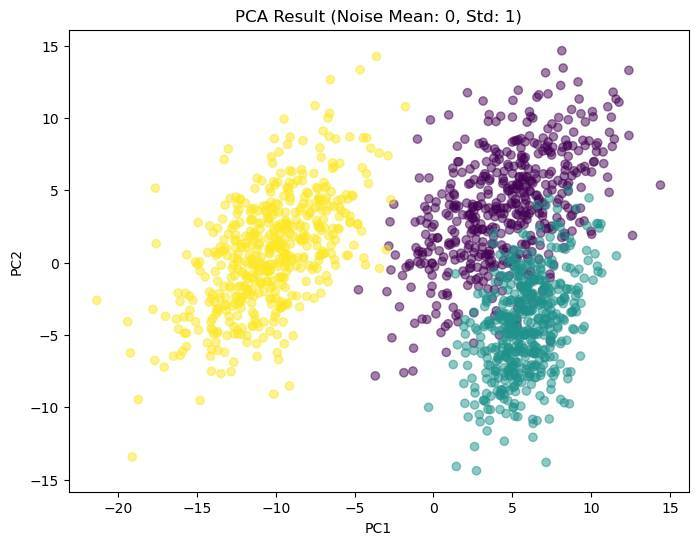

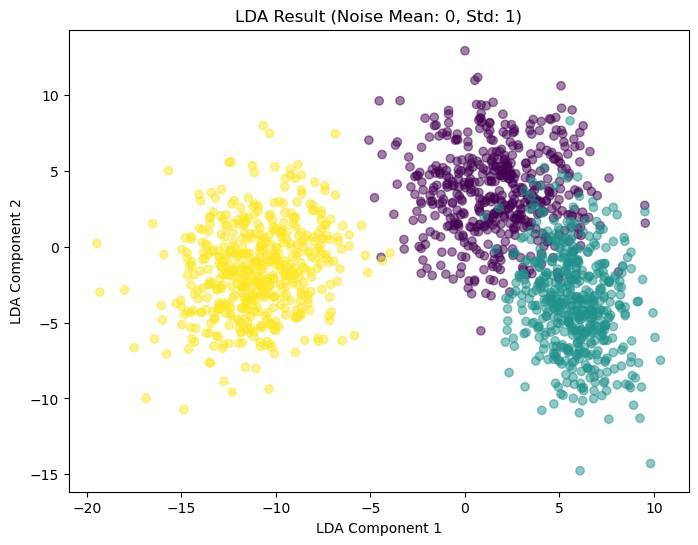

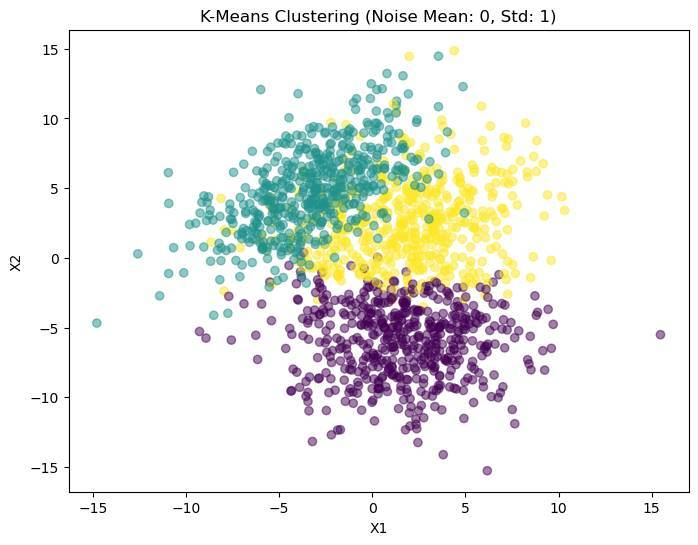

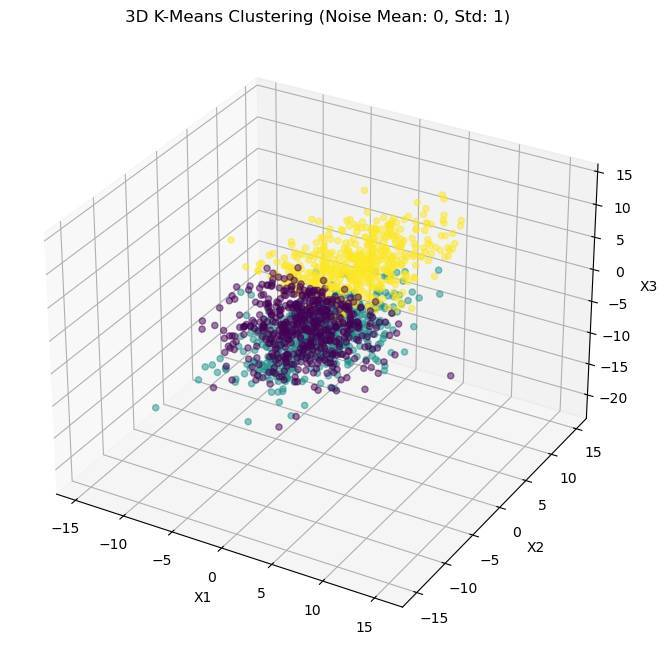

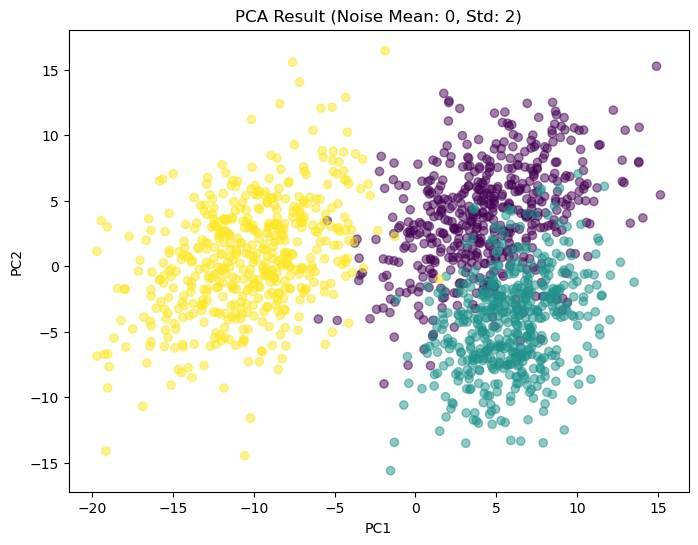

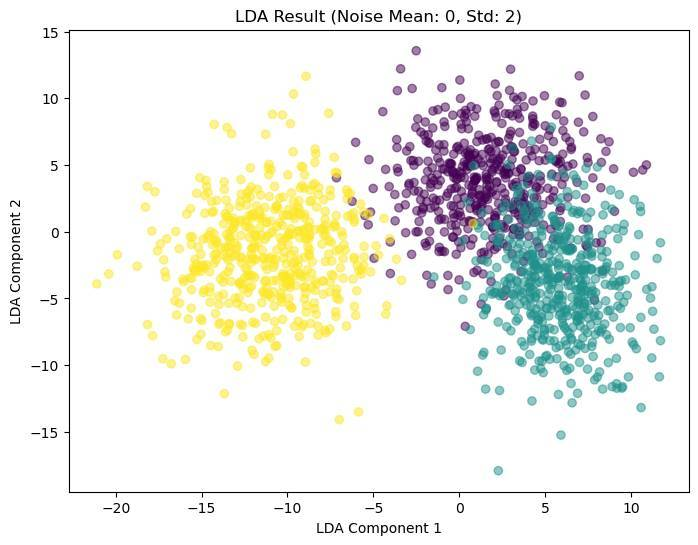

[Some figures were removed to keep the repository small; see report.pdf]


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define original mean vectors and covariance matrices for the three densities
mu1 = np.array([1, 2, 4])
mu2 = np.array([2, -6, 2])
mu3 = np.array([-3, 5, -10])

Sigma1 = np.array([[9, 4, 10], [4, 9, 6], [10, 6, 4]])
Sigma2 = np.array([[8, 1, 0], [1, 6, 6], [0, 6, 3]])
Sigma3 = np.array([[2, 6, 8], [6, 3, 9], [8, 9, 5]])

num_samples = 500
samples1 = np.random.multivariate_normal(mu1, Sigma1, num_samples)
samples2 = np.random.multivariate_normal(mu2, Sigma2, num_samples)
samples3 = np.random.multivariate_normal(mu3, Sigma3, num_samples)
noisy_data = np.vstack([samples1, samples2, samples3])
labels = np.array([0] * num_samples + [1] * num_samples + [2] * num_samples)

# A function to add noise to the data
def add_noise(data, mu_noise, sigma_noise):
    noise = np.random.normal(mu_noise, sigma_noise, data.shape)
    return data + noise

# Define different noise levels (what have been asked)
noise_levels = [(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (1, 2), (2, 4), (3, 6), (1, 4), (2, 6)]

noisy_data_sets = [add_noise(noisy_data, mu, sigma) for mu, sigma in noise_levels]

# PCA implementation
def pca_custom(data, num_components=2):
    data_centered = data - np.mean(data, axis=0)
    U, S, Vt = np.linalg.svd(data_centered)
    pca_result = np.dot(data_centered, Vt.T[:, :num_components])
    return pca_result

# LDA implementation
def lda_custom(data, labels, num_components=2):
    class_labels = np.unique(labels)
    overall_mean = np.mean(data, axis=0)
    Sb = np.zeros((data.shape[1], data.shape[1]))
    Sw = np.zeros((data.shape[1], data.shape[1]))
    for c in class_labels:
        class_data = data[labels == c]
        class_mean = np.mean(class_data, axis=0)
        Sb += len(class_data) * np.outer(class_mean - overall_mean, class_mean - overall_mean)
        Sw += np.dot((class_data - class_mean).T, (class_data - class_mean))    
    eigvals, eigvecs = np.linalg.eig(np.linalg.inv(Sw).dot(Sb))
    sorted_indices = np.argsort(eigvals)[::-1]
    lda_components = eigvecs[:, sorted_indices[:num_components]]
    lda_result = np.dot(data, lda_components)
    return lda_result

# K-Means implementation
def kmeans_custom(data, k=3, max_iters=100):
    centroids = data[np.random.choice(data.shape[0], k, replace=False)]
    for _ in range(max_iters):
        distances = np.linalg.norm(data[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)
        new_centroids = np.array([data[labels == i].mean(axis=0) for i in range(k)])
        if np.all(centroids == new_centroids):
            break
        centroids = new_centroids
    return labels, centroids

# Experimenting with different noise levels
for i, noisy_data in enumerate(noisy_data_sets):
    mu_noise, sigma_noise = noise_levels[i]    
    pca_result = pca_custom(noisy_data, num_components=2)
    lda_result = lda_custom(noisy_data, labels, num_components=2)
    kmeans_labels, _ = kmeans_custom(noisy_data, k=3)
    assert pca_result.shape[0] == len(labels)
    assert lda_result.shape[0] == len(labels)
    plt.figure(figsize=(8, 6))
    plt.scatter(pca_result[:, 0], pca_result[:, 1], c=labels, cmap='viridis', alpha=0.5)
    plt.title(f'PCA Result (Noise Mean: {mu_noise}, Std: {sigma_noise})')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()
    plt.figure(figsize=(8, 6))
    plt.scatter(lda_result[:, 0], lda_result[:, 1], c=labels, cmap='viridis', alpha=0.5)
    plt.title(f'LDA Result (Noise Mean: {mu_noise}, Std: {sigma_noise})')
    plt.xlabel('LDA Component 1')
    plt.ylabel('LDA Component 2')
    plt.show()
    plt.figure(figsize=(8, 6))
    plt.scatter(noisy_data[:, 0], noisy_data[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.5)
    plt.title(f'K-Means Clustering (Noise Mean: {mu_noise}, Std: {sigma_noise})')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.show()
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(noisy_data[:, 0], noisy_data[:, 1], noisy_data[:, 2], c=kmeans_labels, cmap='viridis', alpha=0.5)
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('X3')
    ax.set_title(f'3D K-Means Clustering (Noise Mean: {mu_noise}, Std: {sigma_noise})')
    plt.show()